# Visit with Us: Tourism Package Purchase Prediction — MLOps Project

**Goal:** Build a reproducible machine-learning workflow that estimates whether a customer will purchase the Wellness Tourism Package (`ProdTaken`), then package it behind a Streamlit interface and automate training with GitHub Actions.

**Submission artifacts:** this executed notebook (HTML), the project source files, a trained model, model evaluation metrics, a GitHub Actions workflow, and a Streamlit app. Public GitHub/Streamlit URLs must be added after deployment because this notebook cannot publish to accounts without your authorization.

## 1. Business context and objective

Manual customer targeting can be inconsistent and time-consuming. This project builds a repeatable pipeline for dataset validation, cleaning, train/test splitting, model selection, evaluation, and model registration. The prediction is intended to support marketing prioritization, not replace human judgment.

## 2. Dataset and target

The supplied file is `tourism.csv`. `ProdTaken` is the binary target: `0` means the customer did not purchase and `1` means the customer purchased. `CustomerID` and the generated index column `Unnamed: 0` are identifiers and are excluded from model features.

In [1]:
from pathlib import Path
import json, subprocess, sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

PROJECT_ROOT = Path.cwd()
# This notebook is stored in the project root, so all paths are relative to this folder.
DATA_PATH = PROJECT_ROOT / "tourism_project" / "data" / "tourism.csv"
assert DATA_PATH.exists(), f"Expected dataset at {DATA_PATH}"
df = pd.read_csv(DATA_PATH)
print(f"Dataset loaded: {df.shape[0]:,} rows × {df.shape[1]} columns")
display(df.head())

Dataset loaded: 4,128 rows × 21 columns


,Unnamed: 0,CustomerID,ProdTaken,Age,TypeofContact,CityTier,DurationOfPitch,Occupation,Gender,NumberOfPersonVisiting,NumberOfFollowups,ProductPitched,PreferredPropertyStar,MaritalStatus,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,NumberOfChildrenVisiting,Designation,MonthlyIncome
0,0,200000,1,41.0,Self Enquiry,3,6.0,Salaried,Female,3,3.0,Deluxe,3.0,Single,1.0,1,2,1,0.0,Manager,20993.0
1,1,200001,0,49.0,Company Invited,1,14.0,Salaried,Male,3,4.0,Deluxe,4.0,Divorced,2.0,0,3,1,2.0,Manager,20130.0
2,2,200002,1,37.0,Self Enquiry,1,8.0,Free Lancer,Male,3,4.0,Basic,3.0,Single,7.0,1,3,0,0.0,Executive,17090.0
3,3,200003,0,33.0,Company Invited,1,9.0,Salaried,Female,2,3.0,Basic,3.0,Divorced,2.0,1,5,1,1.0,Executive,17909.0
4,5,200005,0,32.0,Company Invited,1,8.0,Salaried,Male,3,3.0,Basic,3.0,Single,1.0,0,5,1,1.0,Executive,18068.0


## 3. Data registration and validation

The registration script verifies that the expected customer and interaction columns exist, then prints the dataset shape, missing-value count, target distribution, and descriptive summary. The extra `Unnamed: 0` column is a generated index rather than a business feature.

In [2]:
register = subprocess.run(
    [sys.executable, "tourism_project/model_building/data_register.py"],
    cwd=PROJECT_ROOT, capture_output=True, text=True, check=True
)
print(register.stdout[:9000])

Dataset validation passed: tourism_project/data/tourism.csv
Rows: 4,128 | Columns: 21
Missing values (total): 0
Target distribution (count):
ProdTaken
0    3331
1     797
Column summary:
                           count unique           top  freq           mean          std       min        25%       50%        75%       max
Unnamed: 0                4128.0    NaN           NaN   NaN    2527.763808  1409.439133       0.0    1320.75    2603.5    3748.25    4887.0
CustomerID                4128.0    NaN           NaN   NaN  202527.763808  1409.439133  200000.0  201320.75  202603.5  203748.25  204887.0
ProdTaken                 4128.0    NaN           NaN   NaN       0.193072     0.394757       0.0        0.0       0.0        0.0       1.0
Age                       4128.0    NaN           NaN   NaN      37.231831     9.174521      18.0       31.0      36.0       43.0      61.0
TypeofContact               4128      2  Self Enquiry  2918            NaN          NaN       NaN        NaN     

## 4. Exploratory data analysis

The target is imbalanced, so accuracy alone is not enough. Precision, recall, F1, and ROC-AUC are included in evaluation. Recall is particularly useful when the business wants to identify as many likely buyers as possible, while precision helps avoid spending campaign effort on unlikely buyers.

Missing values by column:


,missing_count
Unnamed: 0,0
CustomerID,0
ProdTaken,0
Age,0
TypeofContact,0
CityTier,0
DurationOfPitch,0
Occupation,0
Gender,0
NumberOfPersonVisiting,0



Target distribution:


,count,percentage
ProdTaken,,
0,3331,80.69
1,797,19.31


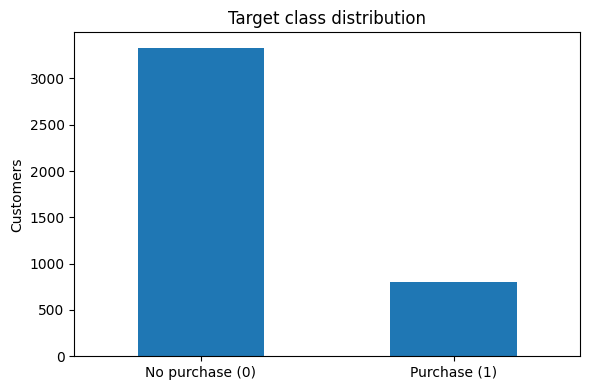

In [3]:
print("Missing values by column:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))
print("\nTarget distribution:")
target_counts = df["ProdTaken"].value_counts().sort_index()
display(pd.DataFrame({
    "count": target_counts,
    "percentage": (target_counts / len(df) * 100).round(2)
}))
fig, ax = plt.subplots(figsize=(6, 4))
target_counts.rename(index={0:"No purchase (0)",1:"Purchase (1)"}).plot(kind="bar", ax=ax)
ax.set_title("Target class distribution")
ax.set_ylabel("Customers")
ax.set_xlabel("")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Observation:** The supplied dataset has 4,128 rows before cleaning. The purchase class is the minority class (about 19%), so the training/test split is stratified and the classifier uses `class_weight="balanced"`. The generated index and customer identifier are removed to reduce leakage from non-generalizable identifiers.

## 5. Data preparation

The preparation script loads the CSV from the repository's `tourism_project/data` folder, removes identifier columns, removes duplicate rows, validates the binary target, normalizes blank/placeholder categorical values, and writes stratified training and testing splits. GitHub Actions transfers the split files between jobs as a workflow artifact.

In [4]:
prep = subprocess.run(
    [sys.executable, "tourism_project/model_building/prep.py"],
    cwd=PROJECT_ROOT, capture_output=True, text=True, check=True
)
print(prep.stdout)
train_df = pd.read_csv(PROJECT_ROOT / "artifacts" / "train.csv")
test_df = pd.read_csv(PROJECT_ROOT / "artifacts" / "test.csv")
print("Training split shape:", train_df.shape)
print("Testing split shape:", test_df.shape)

Cleaned dataset: 4,011 rows; features: 18
Train rows: 3,208; test rows: 803
Train positive rate: 0.193
Test positive rate: 0.193
Saved splits to /mnt/data/visit_with_us_mlops/artifacts

Training split shape: (3208, 19)
Testing split shape: (803, 19)


## 6. Model building, tuning, and experiment tracking

A scikit-learn `Pipeline` applies median imputation to numeric features and most-frequent imputation plus one-hot encoding to categorical features, followed by a class-weighted Random Forest. `GridSearchCV` tunes tree count, maximum depth, and minimum leaf size using stratified 3-fold cross-validation and ROC-AUC scoring.

The training script writes:
- `tourism_project/deployment/model.joblib` — best fitted preprocessing/model pipeline.
- `reports/metrics.json` — best parameters, cross-validation score, test metrics, confusion matrix, and classification report.
- MLflow run metadata when MLflow is installed (included in `requirements.txt` and the GitHub Actions job).

In [5]:
train_run = subprocess.run(
    [sys.executable, "tourism_project/model_building/train.py"],
    cwd=PROJECT_ROOT, capture_output=True, text=True, check=True
)
print(train_run.stdout)
if train_run.stderr.strip():
    print("Warnings / tracking notes:")
    print(train_run.stderr[-2000:])
metrics = json.loads((PROJECT_ROOT / "reports" / "metrics.json").read_text())

Best parameters:
{
  "classifier__max_depth": null,
  "classifier__max_features": "sqrt",
  "classifier__min_samples_leaf": 1,
  "classifier__n_estimators": 250
}
Test metrics:
{
  "accuracy": 0.8978829389788294,
  "precision": 0.9397590361445783,
  "recall": 0.5032258064516129,
  "f1": 0.6554621848739496,
  "roc_auc": 0.967652329749104,
  "best_cv_roc_auc": 0.9400970087555507,
  "training_rows": 3208,
  "testing_rows": 803,
  "model": "RandomForestClassifier"
}
Confusion matrix [ [TN, FP], [FN, TP] ]:
[[643   5]
 [ 77  78]]
Classification report:
              precision    recall  f1-score   support

           0       0.89      0.99      0.94       648
           1       0.94      0.50      0.66       155

    accuracy                           0.90       803
   macro avg       0.92      0.75      0.80       803
weighted avg       0.90      0.90      0.89       803

Saved model: /mnt/data/visit_with_us_mlops/tourism_project/deployment/model.joblib
Saved metrics: /mnt/data/visit_with_

## 7. Model evaluation

,Metric,Value
0,accuracy,0.8979
1,precision,0.9398
2,recall,0.5032
3,f1,0.6555
4,roc_auc,0.9677
5,best_cv_roc_auc,0.9401


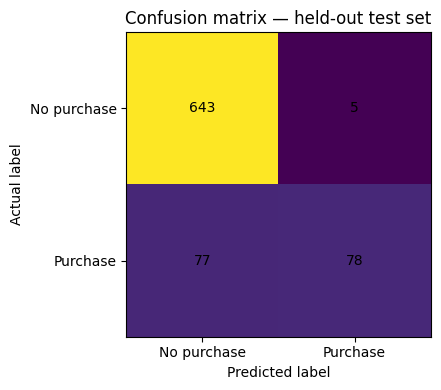

Best tuned parameters:
{
  "classifier__max_depth": null,
  "classifier__max_features": "sqrt",
  "classifier__min_samples_leaf": 1,
  "classifier__n_estimators": 250
}


In [6]:
metric_names = ["accuracy", "precision", "recall", "f1", "roc_auc", "best_cv_roc_auc"]
metric_table = pd.DataFrame({
    "Metric": metric_names,
    "Value": [metrics[k] for k in metric_names]
})
display(metric_table.style.format({"Value": "{:.4f}"}))
cm = np.array(metrics["confusion_matrix"])
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm)
ax.set_title("Confusion matrix — held-out test set")
ax.set_xlabel("Predicted label")
ax.set_ylabel("Actual label")
ax.set_xticks([0,1], labels=["No purchase", "Purchase"])
ax.set_yticks([0,1], labels=["No purchase", "Purchase"])
for (i,j), value in np.ndenumerate(cm):
    ax.text(j, i, str(value), ha="center", va="center")
plt.tight_layout()
plt.show()
print("Best tuned parameters:")
print(json.dumps(metrics["best_params"], indent=2))

### Evaluation observations and business interpretation

- The test set contains 803 rows; the split is stratified to preserve the target distribution.
- ROC-AUC measures ranking quality across thresholds and should be read alongside precision and recall.
- At the default 0.50 threshold, the model is conservative about predicting a purchase: precision is high, while recall is lower. If missing a potential buyer is costly, evaluate a lower threshold on validation data and compare campaign capacity and false-positive costs before deployment.
- These are offline results on one held-out split, not a guarantee of future campaign performance. Monitor results after deployment and retrain when customer behavior or data quality changes.

## 8. Streamlit deployment

The app is `tourism_project/deployment/app.py`. It loads the committed `model.joblib`, captures customer details, creates a one-row pandas DataFrame using the same feature names as training, and displays the estimated purchase probability.

**Deployment steps**
1. Push the project to a GitHub repository and ensure the Actions workflow succeeds and commits `model.joblib`.
2. Open [Streamlit Community Cloud](https://share.streamlit.io/) and create an app from the repository's `main` branch.
3. Set the main file path to `tourism_project/deployment/app.py`.
4. Keep `requirements.txt` in the repository root so Streamlit can install dependencies.
5. Make the app public if required by the rubric, then paste its public URL in the section below.

**GitHub repository URL:** `ADD_PUBLIC_GITHUB_REPOSITORY_URL`  
**Streamlit app URL:** `ADD_PUBLIC_STREAMLIT_APP_URL`

These are placeholders until the repository and app are actually published; no links are fabricated here.

## 9. GitHub Actions CI/CD pipeline

Workflow file: `.github/workflows/pipeline.yml`

The workflow has three dependent jobs:
1. **register-dataset:** validates required columns and summarizes the dataset.
2. **prepare-data:** cleans and splits the dataset, then uploads train/test CSVs as a workflow artifact.
3. **train-evaluate-and-register:** downloads the artifact, tunes and evaluates the model, logs parameters/metrics, and commits the model plus metrics to `main`.

The commit uses `[skip ci]` and the workflow ignores model/metrics paths to prevent recursive pipeline runs. In GitHub repository settings, allow Actions to write repository contents. Never commit a personal access token.

In [7]:
workflow_path = PROJECT_ROOT / ".github" / "workflows" / "pipeline.yml"
print("Workflow exists:", workflow_path.exists())
print("\nWorkflow job names:")
for line in workflow_path.read_text().splitlines():
    if line.strip().endswith(":") and line.startswith("  "):
        print("-", line.strip()[:-1])

Workflow exists: True

Workflow job names:
- push
- paths-ignore
- workflow_dispatch
- register-dataset
- steps
- with
- prepare-data
- steps
- with
- with
- train-evaluate-and-register
- steps
- with
- with


## 10. Final summary and next steps

**What is implemented:** dataset validation, reproducible preprocessing and split generation, tuned Random Forest model, evaluation report, serialized inference pipeline, Streamlit app, dependencies, README, and GitHub Actions workflow.

**Before submission, complete these account-dependent tasks:**
- Push the folder to your own public GitHub repository.
- Check the GitHub Actions run and capture a screenshot showing a successful workflow and repository folder structure.
- Deploy the Streamlit app publicly and capture a screenshot of the working prediction interface.
- Replace the two URL placeholders above with the actual public links.
- Export/submit this executed notebook as HTML.

**Responsible use:** use the probability as decision support, comply with customer-contact and privacy rules, inspect performance across customer groups, and monitor precision/recall and drift after launch.